# 04_02 Limits and Approximations: How Good, and When?

**Learning objectives**
- Know the standard approximations: **Binomial to Poisson**, **Binomial / Poisson / Gamma / chi-square / t to Normal**, **Hypergeometric to Binomial**.
- **Measure** how good an approximation is with exact error measures (the Kolmogorov distance and the total variation distance) instead of guessing.
- Understand where the **rules of thumb** ($np\ge10$, $n/N<0.05$, ...) come from, and test them numerically on a whole grid of parameters.
- Use the **continuity correction** and the **Wilson-Hilferty** transformation, and choose the right approximation for a real problem.

**Prerequisites:** [04_01 The family tree](04_01_relationship_map.ipynb), [01_01 Binomial](../../module_01_discrete/notebooks/01_01_bernoulli_binomial.ipynb), [01_03 Poisson](../../module_01_discrete/notebooks/01_03_poisson.ipynb), [02_08 t and chi-square](../../module_02_continuous/notebooks/02_08_t_chisquare_f.ipynb).

## 1. Setup

All imports in one cell; the generator is seeded so every run gives the same numbers.

In [1]:
import sys
sys.path.append("../..")  # repo root, so common.style can be imported
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.graph_objects as go
from scipy import stats
from common.style import apply_style, MAIN, SIM, HIGHLIGHT, NEUTRAL, COLORS

apply_style()
rng = np.random.default_rng(42)  # fixed seed so every run gives the same numbers

## 2. Prerequisite recap

- **Central Limit Theorem:** a sum (or average) of many independent, finite-variance variables is approximately Normal.
- **CDF:** $F(x)=P(X\le x)$; two distributions are close if their CDFs are close.
- **Continuity correction:** a discrete count $X$ approximated by a continuous Normal: $P(X\le k)\approx\Phi\big(\frac{k+0.5-\mu}\sigma\big)$ (the bar at $k$ occupies $[k-\tfrac12,k+\tfrac12]$).
- **Skewness:** $E[((X-\mu)/\sigma)^3]$; the Normal has skewness 0, so skewed distributions are harder to approximate by a Normal.

## 3. Intuition and story

Exact formulas can be heavy: the exact Binomial tail $P(X\ge10)$ for $n=2000$ needs a sum of binomial coefficients with enormous numbers; in 1950 that was a real obstacle and today it is still useful to *see* the structure. **Approximations** replace a complicated distribution by a simple one (Poisson, Normal) that is easy to compute and to understand.

But an approximation is only as good as its **assumptions**. "Use the Normal for the Binomial" is fine for 1,000 coin flips and terrible for 5 flips of a rare event. The goal of this lesson is not to memorize "np ≥ 10" but to understand **why** the rule exists, and **how big the error is** when it is violated. Every claim below is backed by a number computed exactly.

Three error measures:
- **Kolmogorov distance** $d_K=\max_x|F(x)-G(x)|$: the worst gap between CDFs (any probability $P(X\le x)$ is off by at most $d_K$).
- **Total variation distance** $d_{TV}=\tfrac12\sum_k|p(k)-q(k)|$ for PMFs: any event's probability is off by at most $d_{TV}$.
- **A specific tail probability** (what you actually need): compare the exact and approximate value.

## 4. Formal definition: the approximations and their error bounds

| Approximation | Statement | Rule of thumb | Error guidance |
|---|---|---|---|
| Binomial $\to$ Poisson | Bin$(n,p)\approx$ Poi$(np)$ | $n\ge20$, $p\le0.05$ | **Le Cam:** $d_{TV}\le np^2$ |
| Binomial $\to$ Normal | Bin$(n,p)\approx N(np,np(1-p))$ | $np(1-p)\ge10$ (or $np,n(1-p)\ge10$) | **Berry-Esseen:** $d_K\le0.4748\,\dfrac{p^2+(1-p)^2}{\sqrt{np(1-p)}}$ |
| Poisson $\to$ Normal | Poi$(\lambda)\approx N(\lambda,\lambda)$ | $\lambda\ge20$ | error $\sim$ skewness $=1/\sqrt\lambda$ |
| Gamma $\to$ Normal | Gamma$(k)\approx N(k,k)$ | $k\ge30$ | error $\sim$ skewness $=2/\sqrt k$ |
| Chi-square $\to$ Normal | $\chi^2_\nu\approx N(\nu,2\nu)$; better: **Wilson-Hilferty** | $\nu\ge50$ (plain); any $\nu$ (WH) | cube-root transform kills most skewness |
| t $\to$ Normal | $t_\nu\approx N(0,1)$ | $\nu\ge30$ | critical values: 2.04 vs 1.96 at $\nu=30$ |
| Hypergeometric $\to$ Binomial | Hyp$(N,K,n)\approx$ Bin$(n,K/N)$ | $n/N\le0.05$ | variance ratio = finite-population correction $\frac{N-n}{N-1}$ |

**Wilson-Hilferty:** $\big(\chi^2_\nu/\nu\big)^{1/3}\approx N\Big(1-\frac2{9\nu},\ \frac2{9\nu}\Big)$.

## 5. Derivations

### 5.1 Why Poisson approximates the Binomial (Le Cam in words)
With $p=\lambda/n$: $\binom nkp^k(1-p)^{n-k}\to e^{-\lambda}\lambda^k/k!$ (01_03). Le Cam's inequality makes it quantitative: replacing each Bernoulli($p$) by a Poisson($p$) changes the distribution by at most $p^2$ in total variation (since $P(\text{Bernoulli}\ne\text{Poisson-coupled})\approx p^2$), and the sum of $n$ of them is Poisson($np$), so $d_{TV}\le np^2=\lambda p$. **In plain words.** The error is "the number of trials times the square of the success probability": halve $p$ at fixed $\lambda$ and the error halves.

### 5.2 Why the Normal approximates the Binomial and the Poisson (CLT and the MGF)
The standardized Poisson has MGF $\exp\!\big(\lambda(e^{t/\sqrt\lambda}-1)-t\sqrt\lambda\big)=\exp\!\big(\lambda(\tfrac{t^2}{2\lambda}+\tfrac{t^3}{6\lambda^{3/2}}+\dots)\big)=\exp\!\big(\tfrac{t^2}2+\tfrac{t^3}{6\sqrt\lambda}+\dots\big)\to e^{t^2/2}$, the standard Normal MGF. The leading error term is the $t^3$ term, i.e. the **skewness** $1/\sqrt\lambda$. The same expansion for the Binomial gives the error proportional to the skewness $\frac{1-2p}{\sqrt{np(1-p)}}$. **In plain words.** The approximation is poor exactly when the distribution is lopsided: small $np$, or $p$ far from $\tfrac12$.

### 5.3 The rule $np(1-p)\ge10$ and Berry-Esseen
The Berry-Esseen theorem bounds the Kolmogorov distance of a standardized sum of $n$ iid variables by $C\rho/(\sigma^3\sqrt n)$ with $C\le0.4748$ and $\rho=E|X-\mu|^3$. For a Bernoulli($p$): $\rho/\sigma^3=\frac{p^2+(1-p)^2}{\sqrt{p(1-p)}}$, so $d_K\le0.4748\frac{p^2+(1-p)^2}{\sqrt{np(1-p)}}$. At $np(1-p)=10$ and $p=\tfrac12$ this is $0.4748\cdot0.5/\sqrt{10}\approx0.075$ (a safe upper bound; the true error is far smaller, about 0.01 to 0.014 with the continuity correction, as we will see).

### 5.4 The continuity correction
A bar of height $P(X=k)$ in a histogram of integers occupies the interval $[k-\tfrac12,k+\tfrac12]$. Matching areas: $P(X\le k)\approx\Phi\big(\frac{k+0.5-\mu}\sigma\big)$. Without the half unit you integrate up to the *edge of the bar's left half* and lose half a bar, an error that does not vanish quickly when $\sigma$ is small.

### 5.5 Wilson-Hilferty for chi-square (and Gamma)
The chi-square is skewed (skewness $\sqrt{8/\nu}$). The cube root of a skewed positive variable is much more symmetric; Wilson and Hilferty (1931) found that $(\chi^2_\nu/\nu)^{1/3}$ is nearly Normal with mean $1-\frac2{9\nu}$ and variance $\frac2{9\nu}$. So $P(\chi^2_\nu\le x)\approx\Phi\Big(\frac{(x/\nu)^{1/3}-(1-\frac2{9\nu})}{\sqrt{2/(9\nu)}}\Big)$. For Gamma($k$) use $\nu=2k$.

### 5.6 Student t and Hypergeometric
$t_\nu=Z/\sqrt{\chi^2_\nu/\nu}$ and $\chi^2_\nu/\nu\to1$ with variance $2/\nu$, so $t_\nu\to Z$; the variance of $t_\nu$ is $\frac\nu{\nu-2}=1+\frac2{\nu-2}$, so the excess spread vanishes like $2/\nu$. The Hypergeometric has variance $np(1-p)\frac{N-n}{N-1}$ versus the Binomial's $np(1-p)$: the ratio is the finite-population correction, close to 1 when $n/N$ is small.

## 6. Properties and relationships

- **Chain:** Hypergeometric $\to$ Binomial $\to$ Poisson $\to$ Normal; each link has its own assumption and error.
- **The error of every Normal approximation is driven by skewness,** so the rules of thumb are really "skewness small enough".
- **Tails are the hard part:** the CDF error is small near the center but the *relative* error far in the tail can be large (a Normal approximation can say 0.0001 where the truth is 0.001).
- **Approximate or exact?** Computers evaluate exact Binomial and Poisson tails instantly, so use approximations for **understanding, mental estimates and proofs**, and exact calculations when a decision depends on a small probability.
- **Better approximations exist:** continuity correction, Wilson-Hilferty, Edgeworth and saddlepoint expansions.

## 7. 2D visuals

### 7.1 Binomial to Poisson: pmfs and the Le Cam bound
With the mean fixed at 3 (p = 3/n), the Binomial pmf converges to the Poisson(3) pmf. Right: the exact total variation distance (dots) against the Le Cam bound n p^2 = 9/n (line).

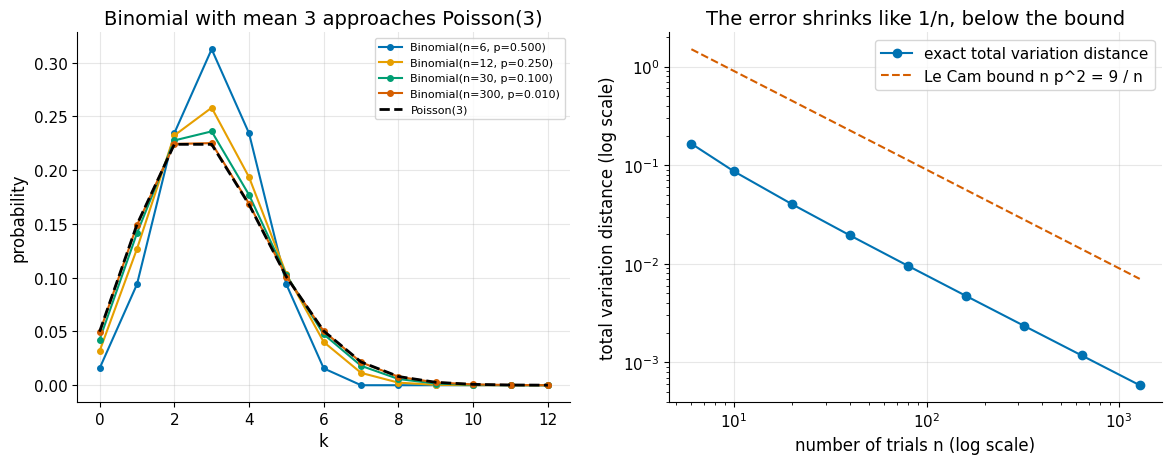

In [2]:
def total_variation_binomial_poisson(n, p):
    """Exact total variation distance between Binomial(n, p) and Poisson(n p)."""
    k = np.arange(0, n + 1)
    tail_of_poisson = stats.poisson(n * p).sf(n)                         # Poisson mass beyond n (the Binomial has none)
    return 0.5 * (np.abs(stats.binom(n, p).pmf(k) - stats.poisson(n * p).pmf(k)).sum() + tail_of_poisson)

fig, (ax_pmf, ax_err) = plt.subplots(1, 2, figsize=(14, 4.8))
ks = np.arange(0, 13)
for n, color in zip([6, 12, 30, 300], COLORS):
    ax_pmf.plot(ks, stats.binom(n, 3 / n).pmf(ks), "o-", markersize=4, color=color, label=f"Binomial(n={n}, p={3 / n:.3f})")
ax_pmf.plot(ks, stats.poisson(3).pmf(ks), "k--", linewidth=2, label="Poisson(3)")
ax_pmf.set_title("Binomial with mean 3 approaches Poisson(3)")
ax_pmf.set_xlabel("k")
ax_pmf.set_ylabel("probability")
ax_pmf.legend(fontsize=8)

n_values = np.array([6, 10, 20, 40, 80, 160, 320, 640, 1280])
tv = [total_variation_binomial_poisson(n, 3 / n) for n in n_values]
ax_err.loglog(n_values, tv, "o-", color=MAIN, label="exact total variation distance")
ax_err.loglog(n_values, 9 / n_values, "--", color=HIGHLIGHT, label="Le Cam bound n p^2 = 9 / n")
ax_err.set_title("The error shrinks like 1/n, below the bound")
ax_err.set_xlabel("number of trials n (log scale)")
ax_err.set_ylabel("total variation distance (log scale)")
ax_err.legend()
plt.show()
assert all(t <= 9 / n for t, n in zip(tv, n_values))

### 7.2 Binomial to Normal: the continuity correction matters
Binomial(30, 0.3): the Normal curve and its CDF with and without the half-unit correction. The corrected CDF follows the staircase through the middle of each step.

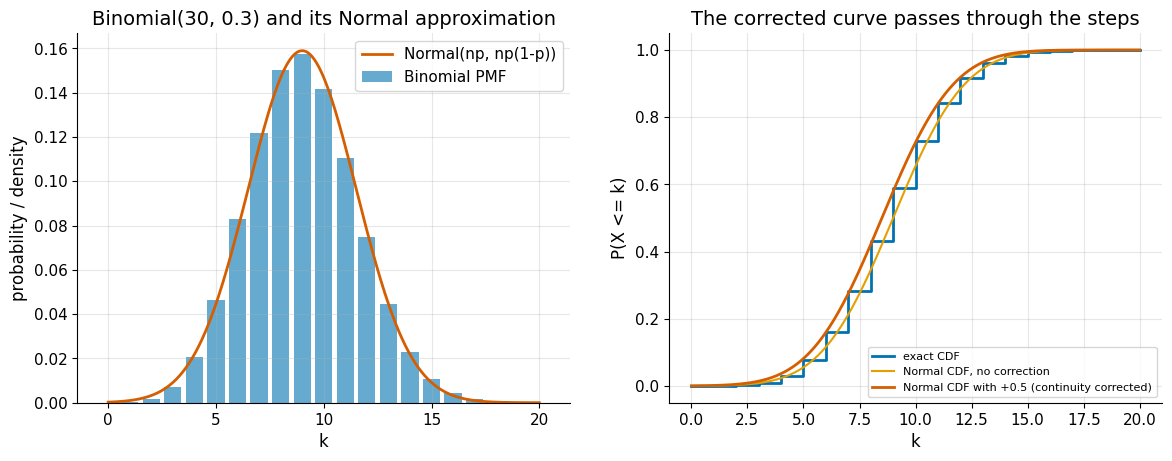

largest CDF gap without correction 0.0888, with correction 0.0105


In [3]:
n, p = 30, 0.3
mu, sd = n * p, np.sqrt(n * p * (1 - p))
ks = np.arange(0, 21)
fig, (ax_pmf, ax_cdf) = plt.subplots(1, 2, figsize=(14, 4.8))
ax_pmf.bar(ks, stats.binom(n, p).pmf(ks), color=MAIN, alpha=0.6, label="Binomial PMF")
x_fine = np.linspace(0, 20, 400)
ax_pmf.plot(x_fine, stats.norm(mu, sd).pdf(x_fine), color=HIGHLIGHT, linewidth=2, label="Normal(np, np(1-p))")
ax_pmf.set_title("Binomial(30, 0.3) and its Normal approximation")
ax_pmf.set_xlabel("k")
ax_pmf.set_ylabel("probability / density")
ax_pmf.legend()
ax_cdf.step(ks, stats.binom(n, p).cdf(ks), where="post", color=MAIN, linewidth=2, label="exact CDF")
ax_cdf.plot(x_fine, stats.norm(mu, sd).cdf(x_fine), color=COLORS[1], label="Normal CDF, no correction")
ax_cdf.plot(x_fine, stats.norm(mu, sd).cdf(x_fine + 0.5), color=HIGHLIGHT, linewidth=2, label="Normal CDF with +0.5 (continuity corrected)")
ax_cdf.set_title("The corrected curve passes through the steps")
ax_cdf.set_xlabel("k")
ax_cdf.set_ylabel("P(X <= k)")
ax_cdf.legend(fontsize=8)
plt.show()
d_plain = np.max(np.abs(stats.binom(n, p).cdf(ks) - stats.norm(mu, sd).cdf(ks)))
d_corrected = np.max(np.abs(stats.binom(n, p).cdf(ks) - stats.norm(mu, sd).cdf(ks + 0.5)))
print(f"largest CDF gap without correction {d_plain:.4f}, with correction {d_corrected:.4f}")

### 7.3 The error is driven by skewness
Across a whole grid of (n, p) values, the Kolmogorov distance of the Normal approximation lines up with the skewness of the Binomial. Left: the error versus skewness. Right: the error versus n p (1 - p), the quantity in the rule of thumb.

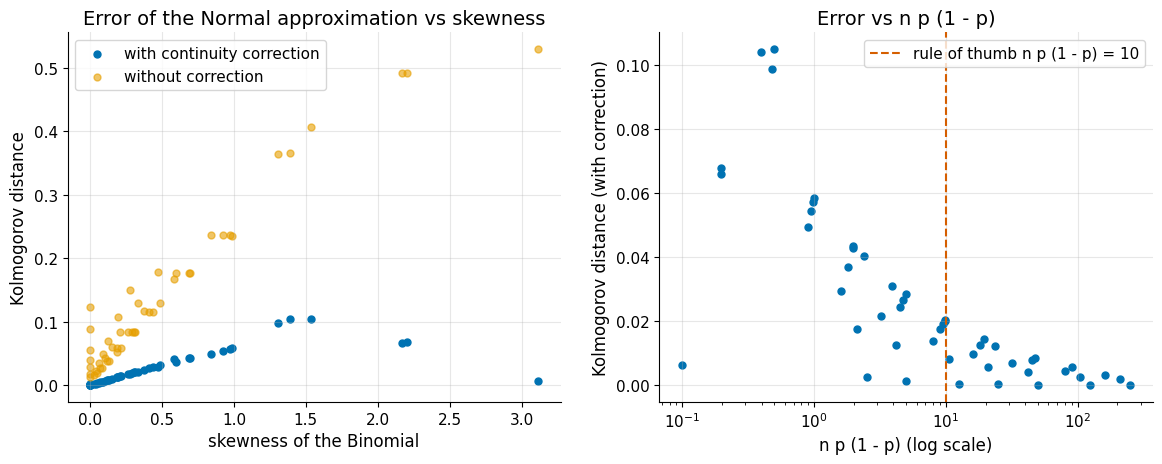

grid points with n p (1-p) >= 10: 20; largest corrected error there = 0.0143; without correction 0.0692
grid points with n p (1-p) < 10: 29; largest corrected error there = 0.1050


In [4]:
def kolmogorov_binomial_normal(n, p, correction=True):
    """Largest gap between the Binomial CDF and its Normal approximation (evaluated at the integers)."""
    k = np.arange(0, n + 1)
    shift = 0.5 if correction else 0.0
    return np.max(np.abs(stats.binom(n, p).cdf(k) - stats.norm(n * p, np.sqrt(n * p * (1 - p))).cdf(k + shift)))

rows = []
for n in [10, 20, 50, 100, 200, 500, 1000]:
    for p in [0.01, 0.02, 0.05, 0.1, 0.2, 0.3, 0.5]:
        rows.append({"n": n, "p": p, "np(1-p)": n * p * (1 - p), "skewness": abs(1 - 2 * p) / np.sqrt(n * p * (1 - p)), "d_K corrected": kolmogorov_binomial_normal(n, p), "d_K plain": kolmogorov_binomial_normal(n, p, False)})
grid_table = pd.DataFrame(rows)

fig, (ax_skew, ax_np) = plt.subplots(1, 2, figsize=(14, 4.8))
ax_skew.scatter(grid_table["skewness"], grid_table["d_K corrected"], s=25, color=MAIN, label="with continuity correction")
ax_skew.scatter(grid_table["skewness"], grid_table["d_K plain"], s=25, color=SIM, alpha=0.6, label="without correction")
ax_skew.set_title("Error of the Normal approximation vs skewness")
ax_skew.set_xlabel("skewness of the Binomial")
ax_skew.set_ylabel("Kolmogorov distance")
ax_skew.legend()
ax_np.scatter(grid_table["np(1-p)"], grid_table["d_K corrected"], s=25, color=MAIN)
ax_np.axvline(10, color=HIGHLIGHT, linestyle="--", label="rule of thumb n p (1 - p) = 10")
ax_np.set_xscale("log")
ax_np.set_title("Error vs n p (1 - p)")
ax_np.set_xlabel("n p (1 - p) (log scale)")
ax_np.set_ylabel("Kolmogorov distance (with correction)")
ax_np.legend()
plt.show()
inside = grid_table[grid_table["np(1-p)"] >= 10]
print(f"grid points with n p (1-p) >= 10: {len(inside)}; largest corrected error there = {inside['d_K corrected'].max():.4f}; without correction {inside['d_K plain'].max():.4f}")
print(f"grid points with n p (1-p) < 10: {len(grid_table) - len(inside)}; largest corrected error there = {grid_table[grid_table['np(1-p)'] < 10]['d_K corrected'].max():.4f}")

### 7.4 Poisson, Gamma and chi-square to Normal
How the error shrinks with the mean. Right panel: Wilson-Hilferty beats the plain Normal approximation for the chi-square by an order of magnitude, even for small degrees of freedom.

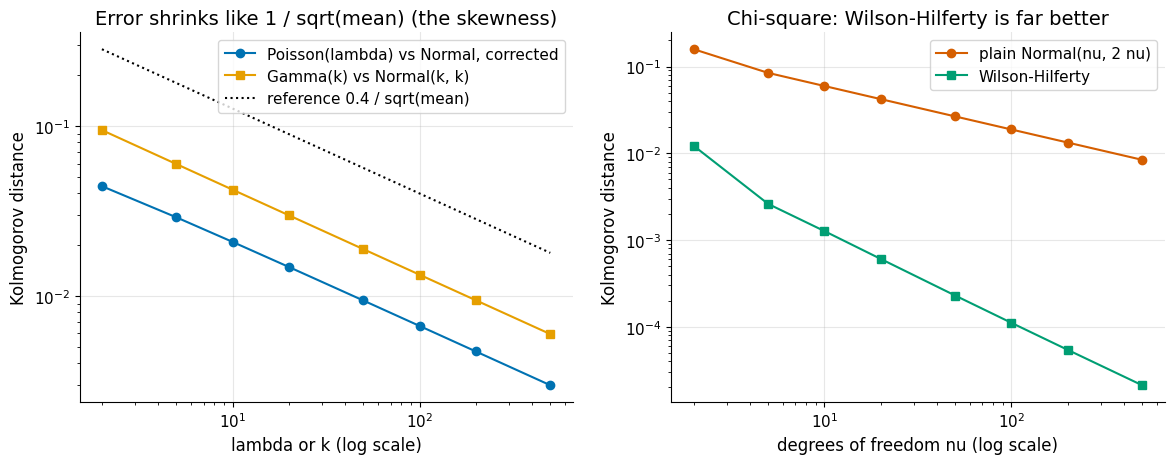

chi-square(5): plain 0.0845  Wilson-Hilferty 0.00261


In [5]:
lam_values = np.array([2, 5, 10, 20, 50, 100, 200, 500])
error_poisson = [np.max(np.abs(stats.poisson(l).cdf(np.arange(0, int(l + 10 * np.sqrt(l) + 10))) - stats.norm(l, np.sqrt(l)).cdf(np.arange(0, int(l + 10 * np.sqrt(l) + 10)) + 0.5))) for l in lam_values]
k_values = np.array([2, 5, 10, 20, 50, 100, 200, 500])
error_gamma = []
for k in k_values:
    x = np.linspace(0.001, k + 10 * np.sqrt(k), 6000)
    error_gamma.append(np.max(np.abs(stats.gamma(k).cdf(x) - stats.norm(k, np.sqrt(k)).cdf(x))))
nu_values = np.array([2, 5, 10, 20, 50, 100, 200, 500])
error_plain, error_wh = [], []
for nu in nu_values:
    x = np.linspace(0.001, nu + 10 * np.sqrt(2 * nu), 6000)
    exact = stats.chi2(nu).cdf(x)
    error_plain.append(np.max(np.abs(exact - stats.norm(nu, np.sqrt(2 * nu)).cdf(x))))
    error_wh.append(np.max(np.abs(exact - stats.norm.cdf(((x / nu) ** (1 / 3) - (1 - 2 / (9 * nu))) / np.sqrt(2 / (9 * nu))))))

fig, (ax_a, ax_b) = plt.subplots(1, 2, figsize=(14, 4.8))
ax_a.loglog(lam_values, error_poisson, "o-", color=COLORS[0], label="Poisson(lambda) vs Normal, corrected")
ax_a.loglog(k_values, error_gamma, "s-", color=COLORS[1], label="Gamma(k) vs Normal(k, k)")
ax_a.loglog(lam_values, 0.4 / np.sqrt(lam_values), "k:", label="reference 0.4 / sqrt(mean)")
ax_a.set_title("Error shrinks like 1 / sqrt(mean) (the skewness)")
ax_a.set_xlabel("lambda or k (log scale)")
ax_a.set_ylabel("Kolmogorov distance")
ax_a.legend()
ax_b.loglog(nu_values, error_plain, "o-", color=COLORS[3], label="plain Normal(nu, 2 nu)")
ax_b.loglog(nu_values, error_wh, "s-", color=COLORS[2], label="Wilson-Hilferty")
ax_b.set_title("Chi-square: Wilson-Hilferty is far better")
ax_b.set_xlabel("degrees of freedom nu (log scale)")
ax_b.set_ylabel("Kolmogorov distance")
ax_b.legend()
plt.show()
print("chi-square(5): plain", round(error_plain[1], 4), " Wilson-Hilferty", round(error_wh[1], 5))
assert all(w < p for w, p in zip(error_wh, error_plain))

### 7.5 Student t to Normal
The t critical values converge to 1.96 slowly: at 30 d.f. the 95 % multiplier is still 2.04 (4 % too small if you use 1.96).

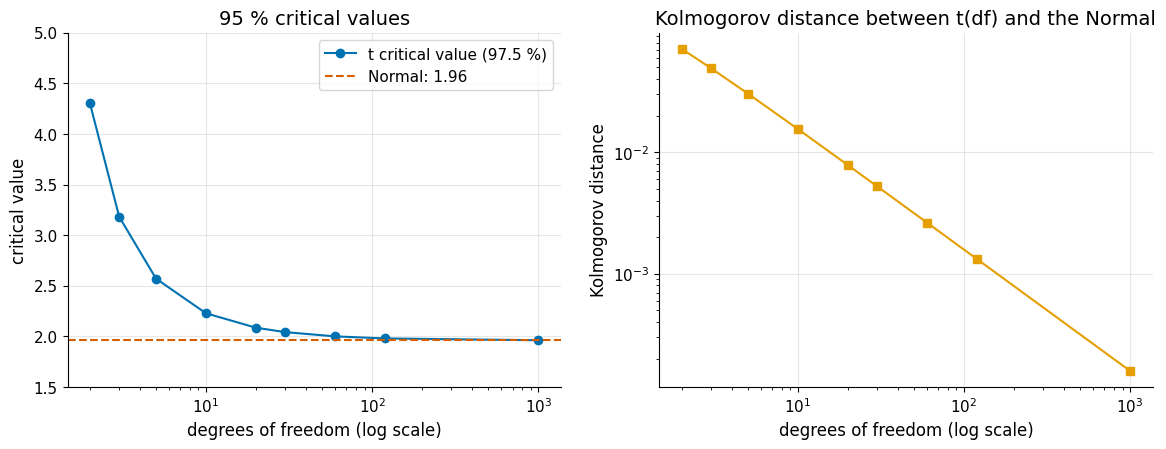

  df  t 97.5 %  error of using 1.96  Kolmogorov distance
   2     4.303                0.544               0.0711
   3     3.182                0.384               0.0493
   5     2.571                0.238               0.0305
  10     2.228                0.120               0.0155
  20     2.086                0.060               0.0078
  30     2.042                0.040               0.0052
  60     2.000                0.020               0.0026
 120     1.980                0.010               0.0013
1000     1.962                0.001               0.0002


In [6]:
df_axis = np.array([2, 3, 5, 10, 20, 30, 60, 120, 1000])
fig, (ax_c, ax_e) = plt.subplots(1, 2, figsize=(14, 4.6))
ax_c.semilogx(df_axis, stats.t.ppf(0.975, df_axis), "o-", color=MAIN, label="t critical value (97.5 %)")
ax_c.axhline(stats.norm.ppf(0.975), color=HIGHLIGHT, linestyle="--", label="Normal: 1.96")
ax_c.set_title("95 % critical values")
ax_c.set_xlabel("degrees of freedom (log scale)")
ax_c.set_ylabel("critical value")
ax_c.set_ylim(1.5, 5)
ax_c.legend()
x = np.linspace(-8, 8, 8001)
gaps = [np.max(np.abs(stats.t(d).cdf(x) - stats.norm.cdf(x))) for d in df_axis]
ax_e.loglog(df_axis, gaps, "s-", color=COLORS[1])
ax_e.set_title("Kolmogorov distance between t(df) and the Normal")
ax_e.set_xlabel("degrees of freedom (log scale)")
ax_e.set_ylabel("Kolmogorov distance")
plt.show()
print(pd.DataFrame({"df": df_axis, "t 97.5 %": stats.t.ppf(0.975, df_axis).round(3), "error of using 1.96": (1 - 1.96 / stats.t.ppf(0.975, df_axis)).round(3), "Kolmogorov distance": np.round(gaps, 4)}).to_string(index=False))

### 7.6 Hypergeometric to Binomial: the sampling fraction
For a sample of n = 20 from a population of N (30 % special items), the total variation distance to the Binomial depends on the sampling fraction n / N.

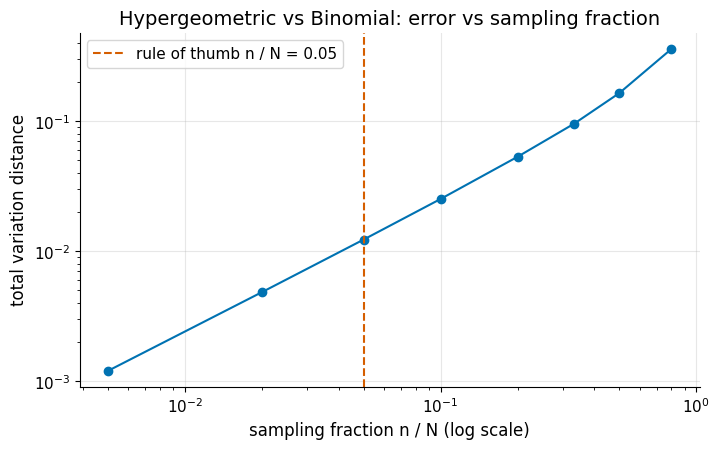

{np.float64(0.8): np.float64(0.3596), np.float64(0.5): np.float64(0.1644), np.float64(0.333): np.float64(0.0958), np.float64(0.2): np.float64(0.0532), np.float64(0.1): np.float64(0.0252), np.float64(0.05): np.float64(0.0123), np.float64(0.02): np.float64(0.0048), np.float64(0.005): np.float64(0.0012)}


In [7]:
N_values = np.array([25, 40, 60, 100, 200, 400, 1000, 4000])
n_sample = 20
tv_hyper = []
for N in N_values:
    K = int(0.3 * N)
    k = np.arange(0, n_sample + 1)
    tv_hyper.append(0.5 * np.abs(stats.hypergeom(N, K, n_sample).pmf(k) - stats.binom(n_sample, K / N).pmf(k)).sum())
fig, ax = plt.subplots(figsize=(8, 4.6))
ax.loglog(n_sample / N_values, tv_hyper, "o-", color=MAIN)
ax.axvline(0.05, color=HIGHLIGHT, linestyle="--", label="rule of thumb n / N = 0.05")
ax.set_title("Hypergeometric vs Binomial: error vs sampling fraction")
ax.set_xlabel("sampling fraction n / N (log scale)")
ax.set_ylabel("total variation distance")
ax.legend()
plt.show()
print(dict(zip((n_sample / N_values).round(3), np.round(tv_hyper, 4))))

## 8. 3D visuals

### 8.1 Static: the error of the Normal approximation over (n, p)
The Kolmogorov distance of Binomial(n, p) from its continuity-corrected Normal. The error is high when n is small or p is near 0 or 1 (the corners where the distribution is lopsided) and falls to a flat floor.

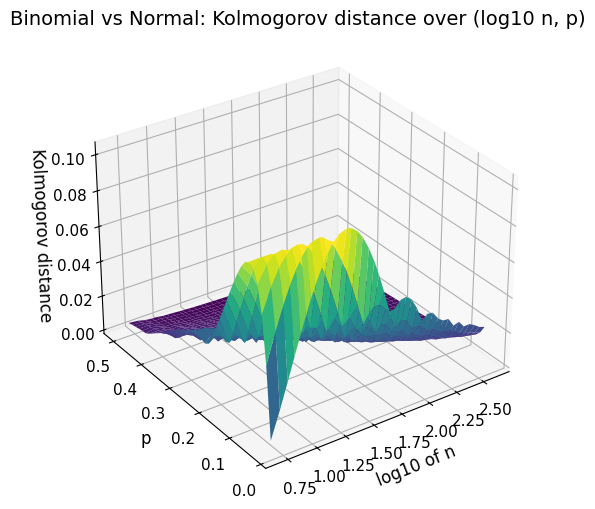

In [8]:
n_axis = np.unique(np.round(np.logspace(np.log10(5), np.log10(400), 40)).astype(int))
p_axis = np.linspace(0.02, 0.5, 40)
error_normal = np.array([[kolmogorov_binomial_normal(n, p) for n in n_axis] for p in p_axis])
N_grid, P_grid = np.meshgrid(np.log10(n_axis), p_axis)
fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(projection="3d")
ax.plot_surface(N_grid, P_grid, error_normal, cmap="viridis", edgecolor="none")
ax.set_title("Binomial vs Normal: Kolmogorov distance over (log10 n, p)")
ax.set_xlabel("log10 of n")
ax.set_ylabel("p")
ax.set_zlabel("Kolmogorov distance")
ax.view_init(elev=30, azim=-125)
plt.show()

### 8.2 Static: the error of the Poisson approximation over (n, p)
Total variation distance of Binomial(n, p) from Poisson(n p). The error grows with p (it is about n p^2 / 2): the Poisson is excellent only for small p, whatever n.

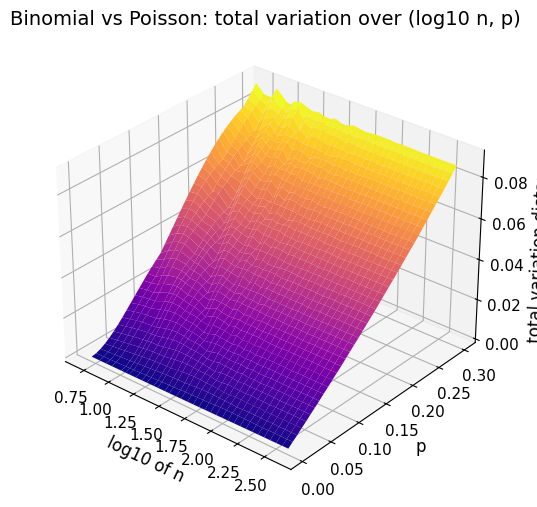

Le Cam's bound n p^2 holds at every one of 1360 grid points


In [9]:
p_small = np.linspace(0.002, 0.3, 40)
n_values2 = np.unique(np.round(np.logspace(np.log10(5), np.log10(400), 35)).astype(int))
error_poisson_grid = np.array([[total_variation_binomial_poisson(n, p) for n in n_values2] for p in p_small])
NG, PG = np.meshgrid(np.log10(n_values2), p_small)
fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(projection="3d")
ax.plot_surface(NG, PG, error_poisson_grid, cmap="plasma", edgecolor="none")
ax.set_title("Binomial vs Poisson: total variation over (log10 n, p)")
ax.set_xlabel("log10 of n")
ax.set_ylabel("p")
ax.set_zlabel("total variation distance")
ax.view_init(elev=30, azim=-50)
plt.show()
assert np.all(error_poisson_grid <= np.outer(p_small**2, n_values2) + 1e-12)          # Le Cam holds on the whole grid
print("Le Cam's bound n p^2 holds at every one of", error_poisson_grid.size, "grid points")

### 8.3 Interactive Plotly version of 8.1
Hover over the surface to read the error for any (n, p); the corner of small n or extreme p is the danger zone.

In [10]:
fig = go.Figure(go.Surface(x=n_axis, y=p_axis, z=error_normal, colorscale="Viridis"))
fig.update_layout(title="Kolmogorov distance: Binomial(n, p) vs continuity-corrected Normal", width=750, height=550,
                  scene=dict(xaxis_title="n", yaxis_title="p", zaxis_title="Kolmogorov distance", xaxis_type="log"))
fig.show()

### 8.4 The rule-of-thumb regions as a map
A heat map over (n, p) with the contours of the Normal rule (n p (1 - p) = 10) and the Poisson rule (n p squared = 0.1): in the overlap both approximations are safe; outside you should use the exact distribution.

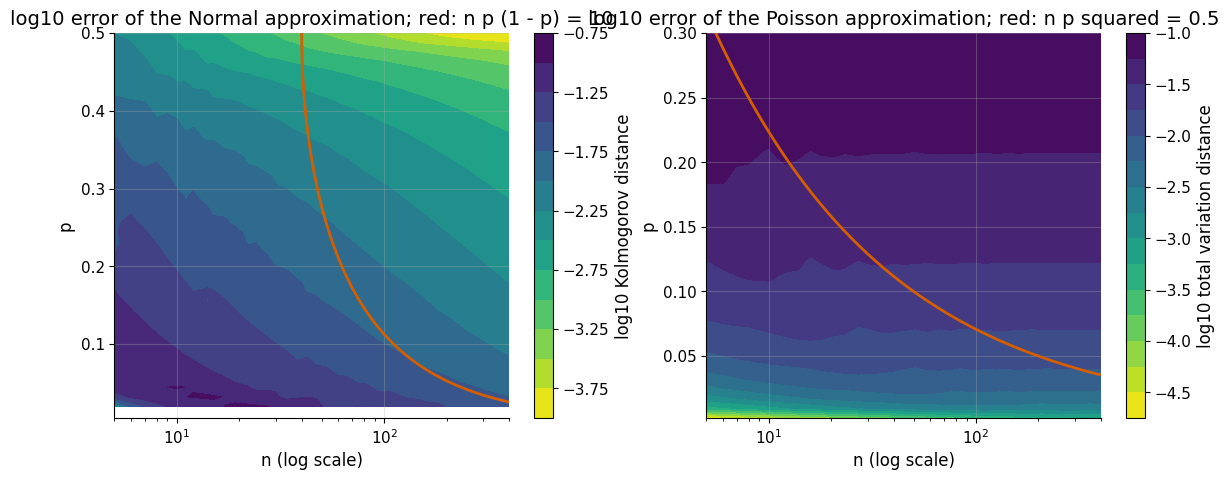

In [11]:
n_fine = np.arange(5, 401)
p_fine = np.linspace(0.005, 0.5, 100)
NN, PP = np.meshgrid(n_fine, p_fine)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
cmap_normal = axes[0].contourf(n_axis, p_axis, np.log10(np.maximum(error_normal, 1e-4)), levels=14, cmap="viridis_r")
axes[0].contour(NN, PP, NN * PP * (1 - PP), levels=[10], colors=[HIGHLIGHT], linewidths=2)
axes[0].set_xscale("log")
axes[0].set_title("log10 error of the Normal approximation; red: n p (1 - p) = 10")
axes[0].set_xlabel("n (log scale)")
axes[0].set_ylabel("p")
plt.colorbar(cmap_normal, ax=axes[0], label="log10 Kolmogorov distance")
cmap_poisson = axes[1].contourf(n_values2, p_small, np.log10(np.maximum(error_poisson_grid, 1e-5)), levels=14, cmap="viridis_r")
axes[1].contour(NN, PP, NN * PP**2, levels=[0.5], colors=[HIGHLIGHT], linewidths=2)
axes[1].set_xscale("log")
axes[1].set_xlim(5, 400); axes[1].set_ylim(0.002, 0.3)
axes[1].set_title("log10 error of the Poisson approximation; red: n p squared = 0.5")
axes[1].set_xlabel("n (log scale)")
axes[1].set_ylabel("p")
plt.colorbar(cmap_poisson, ax=axes[1], label="log10 total variation distance")
plt.show()

## 9. Simulation vs theory

### 9.1 The Central Limit Theorem rate: error shrinks like 1/sqrt(n)
For sums of n Exponential(1) variables (exactly Gamma(n)), the distance to the Normal should shrink at rate 1/sqrt(n), the Berry-Esseen rate. The log-log slope should be about -0.5. We check it with exact formulas and with a simulation.

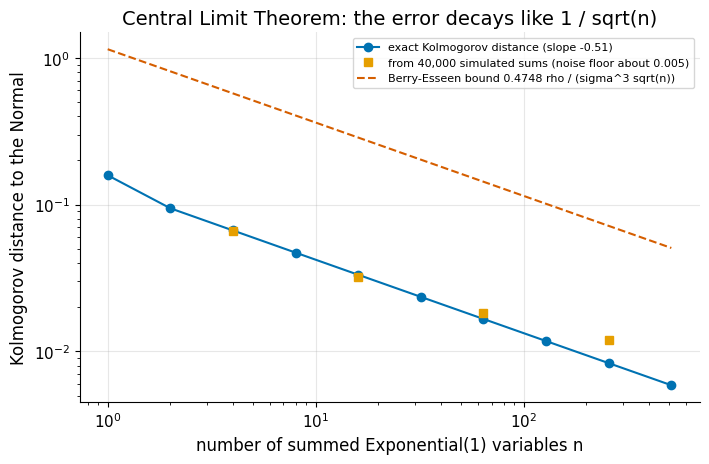

log-log slope of the exact error: -0.514 (theory -0.5)


In [12]:
n_values = np.array([1, 2, 4, 8, 16, 32, 64, 128, 256, 512])
exact_errors = []
for n in n_values:
    x = np.linspace(0.0001, n + 10 * np.sqrt(n), 8000)
    exact_errors.append(np.max(np.abs(stats.gamma(n).cdf(x) - stats.norm(n, np.sqrt(n)).cdf(x))))
slope = np.polyfit(np.log(n_values), np.log(exact_errors), 1)[0]
simulated_errors = []
for n in [4, 16, 64, 256]:
    sums = rng.exponential(1, size=(40_000, n)).sum(axis=1)
    simulated_errors.append(stats.kstest((sums - n) / np.sqrt(n), "norm").statistic)
fig, ax = plt.subplots(figsize=(8, 4.8))
ax.loglog(n_values, exact_errors, "o-", color=MAIN, label=f"exact Kolmogorov distance (slope {slope:.2f})")
ax.loglog([4, 16, 64, 256], simulated_errors, "s", color=SIM, label="from 40,000 simulated sums (noise floor about 0.005)")
ax.loglog(n_values, 0.4748 * (12 / np.e - 2) / np.sqrt(n_values), "--", color=HIGHLIGHT, label="Berry-Esseen bound 0.4748 rho / (sigma^3 sqrt(n))")
ax.set_title("Central Limit Theorem: the error decays like 1 / sqrt(n)")
ax.set_xlabel("number of summed Exponential(1) variables n")
ax.set_ylabel("Kolmogorov distance to the Normal")
ax.legend(fontsize=8)
plt.show()
print(f"log-log slope of the exact error: {slope:.3f} (theory -0.5)")
assert abs(slope + 0.5) < 0.05

### 9.2 Verifying Berry-Esseen and Le Cam numerically
The two theoretical bounds are inequalities: they must hold at every parameter value. We check them on the whole grid (the Berry-Esseen bound is for the plain Normal without continuity correction).

In [13]:
violations_berry = 0
for _, row in grid_table.iterrows():
    n, p = int(row["n"]), row["p"]
    bound = 0.4748 * (p**2 + (1 - p) ** 2) / np.sqrt(n * p * (1 - p))
    exact = kolmogorov_binomial_normal(n, p, correction=False)
    # the discrete CDF jumps, so compare also the left limits; use the larger gap
    k = np.arange(0, n + 1)
    left_gap = np.max(np.abs(stats.binom(n, p).cdf(k - 1) - stats.norm(n * p, np.sqrt(n * p * (1 - p))).cdf(k)))
    if max(exact, left_gap) > bound:
        violations_berry += 1
print("Berry-Esseen violations on the grid:", violations_berry, "of", len(grid_table))
assert violations_berry == 0
ratio = grid_table.assign(bound=lambda d: 0.4748 * (d["p"] ** 2 + (1 - d["p"]) ** 2) / np.sqrt(d["np(1-p)"]))
print("typical ratio bound / actual corrected error:", round(float(np.median(ratio["bound"] / ratio["d_K corrected"])), 1), "(the bound is safe but pessimistic)")

Berry-Esseen violations on the grid: 0 of 49
typical ratio bound / actual corrected error: 8.1 (the bound is safe but pessimistic)


## 10. `scipy.stats` cheat sheet: computing the errors yourself

In [14]:
n, p = 2000, 0.003
exact = stats.binom(n, p)
poisson_approx = stats.poisson(n * p)
normal_approx = stats.norm(n * p, np.sqrt(n * p * (1 - p)))
k = 10
print("exact P(X >= 10) = exact.sf(9)                :", round(exact.sf(9), 5))
print("Poisson approximation: poisson.sf(9)          :", round(poisson_approx.sf(9), 5))
print("Normal with continuity correction: sf(9.5)    :", round(normal_approx.sf(9.5), 5))
print("Normal without correction: sf(10)             :", round(normal_approx.sf(10), 5))
support = np.arange(0, 60)
print("total variation distance Binomial vs Poisson  :", round(0.5 * np.abs(exact.pmf(support) - poisson_approx.pmf(support)).sum(), 5))
print("Kolmogorov distance Binomial vs Poisson       :", round(np.max(np.abs(exact.cdf(support) - poisson_approx.cdf(support))), 5))
print("ks_2samp compares two samples; here a sample against the exact CDF via kstest:", round(stats.kstest(exact.rvs(5000, random_state=1), poisson_approx.cdf).statistic, 4), "(includes sampling noise and discreteness)")

exact P(X >= 10) = exact.sf(9)                : 0.08361
Poisson approximation: poisson.sf(9)          : 0.08392
Normal with continuity correction: sf(9.5)    : 0.07621
Normal without correction: sf(10)             : 0.05098
total variation distance Binomial vs Poisson  : 0.00071
Kolmogorov distance Binomial vs Poisson       : 0.0004
ks_2samp compares two samples; here a sample against the exact CDF via kstest: 0.1615 (includes sampling noise and discreteness)


## 11. Real-world worked examples

---
### Example 1 (main): website clicks and the right approximation for a rare event

**Scenario (illustrative numbers).** A banner is shown to **2,000 visitors** per day and each visitor clicks independently with probability **0.3 %**. Daily clicks $X\sim\text{Bin}(2000,0.003)$, mean 6. Marketing wants an alert when the count is unusually high.

**Questions**
1. What is $P(X\ge10)$ exactly, and with the **Poisson** and **Normal** approximations (with and without the continuity correction)?
2. Which approximation is acceptable, and why? What do the rules of thumb say?
3. What is the smallest alert threshold $c$ such that $P(X\ge c)\le1\%$ (exact, Poisson and Normal)?

### 11.1 By hand
Here $n=2000$, $p=0.003$, $np=6$, $np(1-p)=5.982$.

**Q1.** *Exact:* $P(X\ge10)=1-\sum_{k=0}^{9}\binom{2000}k0.003^k0.997^{2000-k}$ (sum written out in code). *Poisson(6):* $1-e^{-6}\sum_{k=0}^9\frac{6^k}{k!}=1-0.9161=0.0839$. *Normal:* $\sigma=\sqrt{5.982}=2.446$; with correction $z=\frac{9.5-6}{2.446}=1.431$, so $1-\Phi(1.431)=0.0762$; without correction $z=\frac{10-6}{2.446}=1.635$, giving $0.0510$.

**Q2.** Rules of thumb: $np=6<10$, so the **Normal rule fails**; $n=2000\ge20$ and $p=0.003\le0.05$, so the **Poisson rule holds** (Le Cam: $d_{TV}\le np^2=0.018$). The Binomial is skewed (skewness $\frac{1-2p}{\sqrt{np(1-p)}}=0.41$) so the Normal curve is off.

**Q3.** The threshold is the smallest integer $c$ with $P(X\ge c)\le0.01$, found by scanning candidate values in code; the Normal approximation suggests $c\approx6+2.326\cdot2.446+0.5=12.2$, so $c=13$.

In [15]:
import math

n_visitors, p_click = 2000, 0.003
mean_clicks = n_visitors * p_click
sd_clicks = math.sqrt(n_visitors * p_click * (1 - p_click))

def binomial_pmf_by_formula(k):
    return math.comb(n_visitors, k) * p_click**k * (1 - p_click) ** (n_visitors - k)

def poisson_pmf_by_formula(k):
    return math.exp(-mean_clicks) * mean_clicks**k / math.factorial(k)

def standard_normal_cdf(z):
    return 0.5 * (1 + math.erf(z / math.sqrt(2)))

exact_hand = 1 - sum(binomial_pmf_by_formula(k) for k in range(10))
poisson_hand = 1 - sum(poisson_pmf_by_formula(k) for k in range(10))
normal_corrected_hand = 1 - standard_normal_cdf((9.5 - mean_clicks) / sd_clicks)
normal_plain_hand = 1 - standard_normal_cdf((10 - mean_clicks) / sd_clicks)
print(f"P(X >= 10): exact {exact_hand:.5f} | Poisson {poisson_hand:.5f} | Normal corrected {normal_corrected_hand:.5f} | Normal plain {normal_plain_hand:.5f}")

def smallest_threshold(tail_function, level=0.01):
    c = 0
    while tail_function(c) > level:        # tail_function(c) = P(X >= c)
        c += 1
    return c

c_exact = smallest_threshold(lambda c: 1 - sum(binomial_pmf_by_formula(k) for k in range(c)))
c_poisson = smallest_threshold(lambda c: 1 - sum(poisson_pmf_by_formula(k) for k in range(c)))
c_normal = smallest_threshold(lambda c: 1 - standard_normal_cdf((c - 0.5 - mean_clicks) / sd_clicks))
print(f"alert threshold for a 1 % false-alarm rate: exact {c_exact}, Poisson {c_poisson}, Normal (corrected) {c_normal}")

P(X >= 10): exact 0.08361 | Poisson 0.08392 | Normal corrected 0.07621 | Normal plain 0.05098
alert threshold for a 1 % false-alarm rate: exact 13, Poisson 13, Normal (corrected) 13


### 11.2 In code with `scipy`, and the asserts

In [16]:
clicks = stats.binom(n_visitors, p_click)
poisson_model = stats.poisson(mean_clicks)
normal_model = stats.norm(mean_clicks, sd_clicks)

assert np.isclose(exact_hand, clicks.sf(9)) and np.isclose(poisson_hand, poisson_model.sf(9))
assert np.isclose(normal_corrected_hand, normal_model.sf(9.5)) and np.isclose(normal_plain_hand, normal_model.sf(10))
assert clicks.sf(c_exact - 1) <= 0.01 < clicks.sf(c_exact - 2)                        # c_exact is the smallest threshold with P(X >= c) <= 0.01
errors = pd.DataFrame({"approximation": ["Poisson(6)", "Normal, corrected", "Normal, plain"], "P(X >= 10)": [poisson_model.sf(9), normal_model.sf(9.5), normal_model.sf(10)]})
errors["error vs exact"] = errors["P(X >= 10)"] - clicks.sf(9)
errors["relative error"] = errors["error vs exact"] / clicks.sf(9)
print(f"exact P(X >= 10) = {clicks.sf(9):.5f}")
print(errors.round(5).to_string(index=False))
support = np.arange(0, 40)
print(f"Kolmogorov distances: Poisson {np.max(np.abs(clicks.cdf(support) - poisson_model.cdf(support))):.4f}, Normal (corrected) {np.max(np.abs(clicks.cdf(support) - normal_model.cdf(support + 0.5))):.4f}")
print(f"Le Cam bound n p^2 = {n_visitors * p_click**2:.4f}; skewness = {(1 - 2 * p_click) / sd_clicks:.3f}")

exact P(X >= 10) = 0.08361
    approximation  P(X >= 10)  error vs exact  relative error
       Poisson(6)     0.08392         0.00031         0.00371
Normal, corrected     0.07621        -0.00740        -0.08852
    Normal, plain     0.05098        -0.03264        -0.39032
Kolmogorov distances: Poisson 0.0004, Normal (corrected) 0.0264
Le Cam bound n p^2 = 0.0180; skewness = 0.406


### 11.3 Verify by simulation

In [17]:
days = rng.binomial(n_visitors, p_click, size=2_000_000)
print(f"P(X >= 10): exact {clicks.sf(9):.5f}, simulated {np.mean(days >= 10):.5f}")
print(f"threshold {c_exact}: P(X >= {c_exact}) exact {clicks.sf(c_exact - 1):.5f}, simulated {np.mean(days >= c_exact):.5f}; with the Normal threshold {c_normal}: exact false-alarm rate {clicks.sf(c_normal - 1):.5f}")
assert abs(np.mean(days >= 10) - clicks.sf(9)) < 0.0005

P(X >= 10): exact 0.08361, simulated 0.08359
threshold 13: P(X >= 13) exact 0.00873, simulated 0.00873; with the Normal threshold 13: exact false-alarm rate 0.00873


### 11.4 Plots with the regions shaded

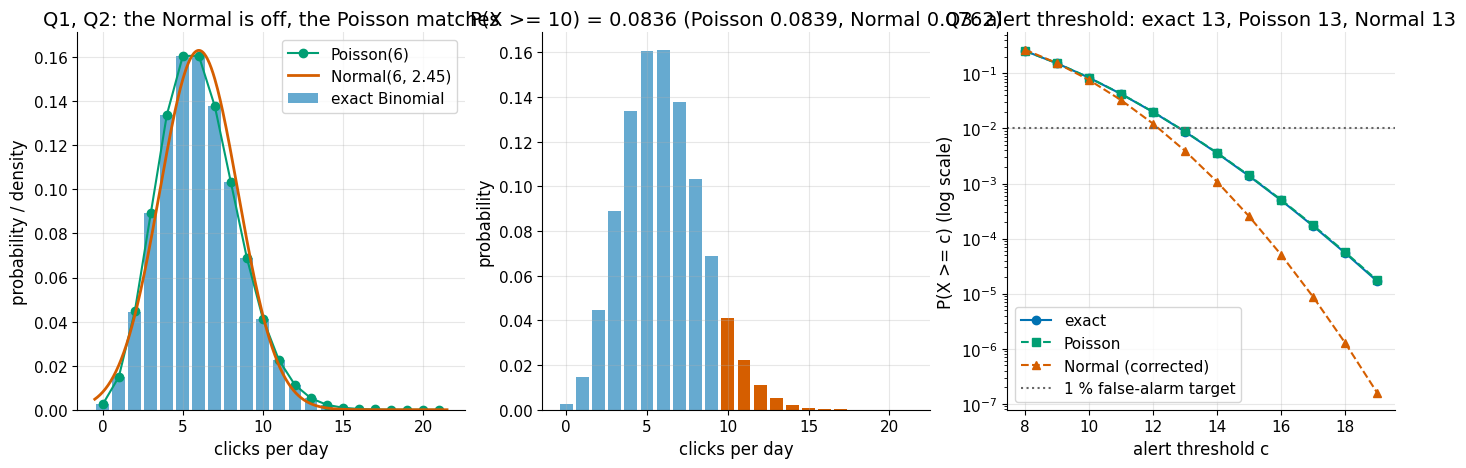

In [18]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.9))
ks = np.arange(0, 22)
axes[0].bar(ks, clicks.pmf(ks), color=MAIN, alpha=0.6, label="exact Binomial")
axes[0].plot(ks, poisson_model.pmf(ks), "o-", color=COLORS[2], label="Poisson(6)")
x_fine = np.linspace(-0.5, 21.5, 400)
axes[0].plot(x_fine, normal_model.pdf(x_fine), color=HIGHLIGHT, linewidth=2, label="Normal(6, 2.45)")
axes[0].set_title("Q1, Q2: the Normal is off, the Poisson matches")
axes[0].set_xlabel("clicks per day")
axes[0].set_ylabel("probability / density")
axes[0].legend()

tail = ks >= 10
axes[1].bar(ks, clicks.pmf(ks), color=MAIN, alpha=0.6)
axes[1].bar(ks[tail], clicks.pmf(ks[tail]), color=HIGHLIGHT)
axes[1].set_title(f"P(X >= 10) = {clicks.sf(9):.4f} (Poisson {poisson_model.sf(9):.4f}, Normal {normal_model.sf(9.5):.4f})")
axes[1].set_xlabel("clicks per day")
axes[1].set_ylabel("probability")

thresholds = np.arange(8, 20)
axes[2].semilogy(thresholds, clicks.sf(thresholds - 1), "o-", color=MAIN, label="exact")
axes[2].semilogy(thresholds, poisson_model.sf(thresholds - 1), "s--", color=COLORS[2], label="Poisson")
axes[2].semilogy(thresholds, normal_model.sf(thresholds - 0.5), "^--", color=HIGHLIGHT, label="Normal (corrected)")
axes[2].axhline(0.01, color=NEUTRAL, linestyle=":", label="1 % false-alarm target")
axes[2].set_title(f"Q3: alert threshold: exact {c_exact}, Poisson {c_poisson}, Normal {c_normal}")
axes[2].set_xlabel("alert threshold c")
axes[2].set_ylabel("P(X >= c) (log scale)")
axes[2].legend()
plt.show()

### 11.5 Interpretation and decision
- The exact probability of **10 or more clicks is 8.4 %**; the **Poisson gives 8.4 % too** (error under 0.001), while the **Normal gives 7.6 % with the continuity correction and 5.1 % without**: the plain Normal is off by 40 % (relative), a large error in a tail probability.
- The rules agree: np = 6 is far below 10, so the **Normal rule of thumb fails**, but p = 0.003 is tiny, so the **Poisson works** (Le Cam error bound 0.018, true distance far smaller).
- For the **alert threshold** all three methods land on **13 clicks** (true false-alarm rate 0.87 %): a threshold is an integer, and the Normal's error in the far tail happens not to change it here. Do not read that as proof the Normal is fine: the *probability* it reports for 10 or more is 9 % too low (corrected) or 39 % too low (plain).
- **Decision:** use the Poisson (or the exact Binomial, which a computer evaluates instantly) for rare-event counts and set the alert at the exact threshold; never use the Normal when the mean is below about 10.

---
### Example 2: exam passes: when the Normal approximation shines

**Scenario (illustrative).** **200 students** each pass independently with probability **0.6**. What is $P(110\le X\le130)$ passes?

**By hand.** $np=120$, $np(1-p)=48$, $\sigma=6.928$; the Normal rule holds ($np=120$ and $n(1-p)=80$ are both far above 10). With the continuity correction: $P=\Phi\big(\frac{130.5-120}{6.928}\big)-\Phi\big(\frac{109.5-120}{6.928}\big)=\Phi(1.516)-\Phi(-1.516)=0.870$.

In [19]:
n_students, p_pass = 200, 0.6
exam = stats.binom(n_students, p_pass)
sd_exam = math.sqrt(n_students * p_pass * (1 - p_pass))
exact_exam_hand = sum(math.comb(n_students, k) * p_pass**k * (1 - p_pass) ** (n_students - k) for k in range(110, 131))
normal_corrected_exam = standard_normal_cdf((130.5 - 120) / sd_exam) - standard_normal_cdf((109.5 - 120) / sd_exam)
normal_plain_exam = standard_normal_cdf((130 - 120) / sd_exam) - standard_normal_cdf((110 - 120) / sd_exam)
poisson_exam = stats.poisson(120).cdf(130) - stats.poisson(120).cdf(109)
assert np.isclose(exact_exam_hand, exam.cdf(130) - exam.cdf(109))
print(pd.DataFrame({"model": ["exact Binomial", "Normal, corrected", "Normal, plain", "Poisson(120) (wrong model)"],
                    "P(110 <= X <= 130)": [exact_exam_hand, normal_corrected_exam, normal_plain_exam, poisson_exam]}).round(4).to_string(index=False))
simulated = rng.binomial(n_students, p_pass, size=1_000_000)
print(f"simulation: {np.mean((simulated >= 110) & (simulated <= 130)):.4f}; Kolmogorov distance of the corrected Normal: {kolmogorov_binomial_normal(200, 0.6):.4f}")
assert abs(normal_corrected_exam - exact_exam_hand) < 0.002
assert abs(poisson_exam - exact_exam_hand) > 0.05                 # the Poisson is clearly wrong here: np(1-p) = 48 is not 120

                     model  P(110 <= X <= 130)
            exact Binomial              0.8706
         Normal, corrected              0.8704
             Normal, plain              0.8511
Poisson(120) (wrong model)              0.6623
simulation: 0.8707; Kolmogorov distance of the corrected Normal: 0.0019


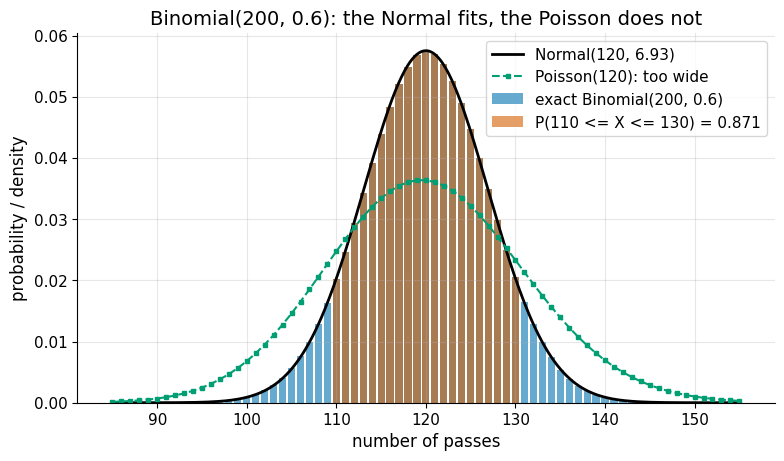

In [20]:
fig, ax = plt.subplots(figsize=(9, 4.8))
ks = np.arange(85, 156)
ax.bar(ks, exam.pmf(ks), color=MAIN, alpha=0.6, label="exact Binomial(200, 0.6)")
band = (ks >= 110) & (ks <= 130)
ax.bar(ks[band], exam.pmf(ks[band]), color=HIGHLIGHT, alpha=0.6, label=f"P(110 <= X <= 130) = {exam.cdf(130) - exam.cdf(109):.3f}")
x_fine = np.linspace(85, 155, 400)
ax.plot(x_fine, stats.norm(120, sd_exam).pdf(x_fine), color="black", linewidth=2, label="Normal(120, 6.93)")
ax.plot(ks, stats.poisson(120).pmf(ks), "s--", markersize=3, color=COLORS[2], label="Poisson(120): too wide")
ax.set_title("Binomial(200, 0.6): the Normal fits, the Poisson does not")
ax.set_xlabel("number of passes")
ax.set_ylabel("probability / density")
ax.legend()
plt.show()

**Interpretation.** About **87 % of the time** between 110 and 130 students pass. The corrected Normal gives 0.870 against the exact 0.870 (error under 0.001), while the Poisson (variance 120 against the true 48) is far off: here the Poisson is the **wrong** tool because p = 0.6 is not small. **Approximations must match the regime:** Poisson for rare events (small p), Normal for large np(1 - p).

---
### Example 3: total waiting time (Gamma to Normal) and the t multiplier

**3a. Gamma to Normal.** The time to serve **40 customers** in a row is the sum of 40 independent Exponential service times with mean 5 minutes: Gamma(40, scale 5), mean 200 and SD 31.6 minutes. What is $P(T>230)$ (the shift overruns)? Exact, plain Normal and Wilson-Hilferty (with $\nu=2k=80$).

**By hand.** Normal: $z=\frac{230-200}{31.62}=0.949$, $P=1-\Phi(0.949)=0.171$. Wilson-Hilferty with $X/k$, $k=40$: $\big(\frac{230}{200}\big)^{1/3}=1.0477$; mean $1-\frac1{9\cdot40}=0.99722$, SD $\sqrt{\frac1{360}}=0.05270$; $z=\frac{1.0477-0.99722}{0.0527}=0.958$, $P=1-\Phi(0.958)=0.169$.

P(T > 230): exact 0.16925 | plain Normal 0.17139 | Wilson-Hilferty 0.16914 | simulated 0.16887


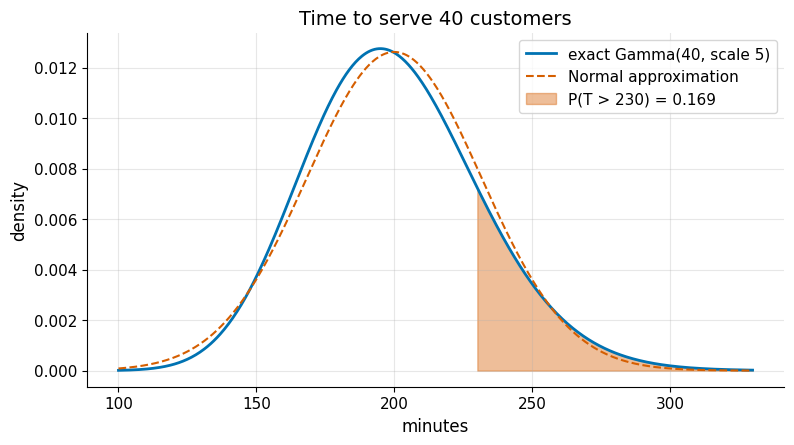

In [21]:
k_customers, scale_minutes = 40, 5.0
shift = stats.gamma(k_customers, scale=scale_minutes)
exact_overrun = shift.sf(230)
plain_normal = 1 - standard_normal_cdf((230 - k_customers * scale_minutes) / (scale_minutes * math.sqrt(k_customers)))
wh_z = (((230 / (k_customers * scale_minutes)) ** (1 / 3)) - (1 - 1 / (9 * k_customers))) / math.sqrt(1 / (9 * k_customers))
wilson_hilferty = 1 - standard_normal_cdf(wh_z)
simulated_shift = rng.exponential(scale_minutes, size=(500_000, k_customers)).sum(axis=1)
print(f"P(T > 230): exact {exact_overrun:.5f} | plain Normal {plain_normal:.5f} | Wilson-Hilferty {wilson_hilferty:.5f} | simulated {np.mean(simulated_shift > 230):.5f}")
assert abs(wilson_hilferty - exact_overrun) < abs(plain_normal - exact_overrun)
assert abs(np.mean(simulated_shift > 230) - exact_overrun) < 0.002
x = np.linspace(100, 330, 600)
fig, ax = plt.subplots(figsize=(9, 4.6))
ax.plot(x, shift.pdf(x), color=MAIN, linewidth=2, label="exact Gamma(40, scale 5)")
ax.plot(x, stats.norm(200, 31.62).pdf(x), "--", color=HIGHLIGHT, label="Normal approximation")
ax.fill_between(x[x > 230], shift.pdf(x[x > 230]), color=HIGHLIGHT, alpha=0.4, label=f"P(T > 230) = {exact_overrun:.3f}")
ax.set_title("Time to serve 40 customers")
ax.set_xlabel("minutes")
ax.set_ylabel("density")
ax.legend()
plt.show()

**3b. The t multiplier.** A 95 % confidence interval uses the multiplier 1.96 (Normal) or the t value. How wrong is 1.96 for a sample of size n?

In [22]:
rows = []
for n in (5, 10, 30, 100, 500):
    t_multiplier = stats.t.ppf(0.975, n - 1)
    data = rng.normal(0, 1, size=(200_000, n))
    means, errors = data.mean(axis=1), data.std(axis=1, ddof=1) / np.sqrt(n)
    rows.append({"n": n, "t multiplier": round(t_multiplier, 3), "coverage using 1.96": np.mean(np.abs(means) <= 1.96 * errors), "coverage using t": np.mean(np.abs(means) <= t_multiplier * errors)})
t_table = pd.DataFrame(rows)
print(t_table.round(4).to_string(index=False))
assert abs(t_table.loc[t_table["n"] == 5, "coverage using 1.96"].iloc[0] - 0.878) < 0.01
assert (abs(t_table["coverage using t"] - 0.95) < 0.003).all()

  n  t multiplier  coverage using 1.96  coverage using t
  5         2.776               0.8795            0.9509
 10         2.262               0.9187            0.9504
 30         2.045               0.9407            0.9507
100         1.984               0.9473            0.9499
500         1.965               0.9490            0.9496


**Interpretation.** *3a:* The exact overrun probability is **0.1692**; the plain Normal says 0.1714 (error 0.002) and **Wilson-Hilferty says 0.1691** (error 0.0001), about 20 times more accurate, and the simulation agrees (0.1689). With 40 customers the Gamma is already close to Normal, but its right skew makes the plain Normal slightly pessimistic on the right tail; the cube-root trick removes that skew, and it matters even more for small shape parameters. *3b:* With **5 observations the 1.96 interval covers the truth only 88 % of the time** (not 95 %); at n = 30 it is 94 %, at n = 100 about 95 %. **Decision:** use the t multiplier for samples below about 100; use 1.96 only for large samples.

## 12. Where it is used

### Statistics
- **Large-sample inference:** the CLT-based z tests and intervals, Wald intervals for proportions (Normal approximation to the Binomial), chi-square tests (the Normal limit of multinomial counts).
- **Exactness checks:** exact Binomial (Clopper-Pearson) and Poisson intervals when the Normal approximation fails (small counts, rare events).

### Data science
- **A/B testing:** the z-test for conversion rates assumes $np(1-p)$ large in each arm; for tiny conversion counts use exact or Poisson methods.
- **Alert thresholds and capacity planning** for event counts (Poisson/Normal depending on the mean); sample-size calculations.

### ML and AI
- **Gaussian approximations of posteriors** (Laplace approximation, variational inference); the CLT behind stochastic-gradient noise; Poisson approximations for sparse count features and token counts.

## 13. Common pitfalls and misconceptions

- **Rules of thumb are guidelines, not guarantees:** the error depends on the skewness and on *which* probability you need (tails are harder than the center).
- **Forgetting the continuity correction** for discrete counts: the error can be several times larger (Example 1).
- **Using the Poisson when p is not small** (Example 2) or the Normal when the mean is small (Example 1).
- **Relative error in the tail** can be large even when the CDF error looks tiny: compare the tail probability you need.
- **Approximating when you do not have to:** exact Binomial, Poisson, Gamma and t probabilities are one function call.
- **The CLT needs finite variance:** heavy tails (Pareto with alpha at most 2, Cauchy) break every Normal approximation.
- **1.96 is for large samples only:** with small samples the t multiplier is larger.

## 14. Exercises

1. A factory has a 0.4 % defect rate and ships boxes of 500. Using the exact Binomial, the Poisson and the corrected Normal, compute the probability of at least 5 defects in a box and comment on the three answers.
2. For $\text{Bin}(n,0.1)$, find by computation the smallest $n$ for which the continuity-corrected Normal approximation has Kolmogorov distance below 0.01. Compare with the rule $np(1-p)\ge10$ (and try $p=0.5$ too).
3. For the chi-square with 10 d.f., compute $P(\chi^2_{10}>18.31)$ exactly, with the plain Normal(10, 20) approximation, and with Wilson-Hilferty.
4. A poll samples 400 people from a city of 12,000 (30 % favour a proposal). Is the Binomial an acceptable model for the number in favour? Compare the exact Hypergeometric and Binomial variances.
5. Verify Le Cam's bound $d_{TV}\le np^2$ for $n=100$, $p=0.05$, and for $n=100$, $p=0.3$. Is the bound informative in the second case?
6. (Harder) Show that the t distribution's variance $\nu/(\nu-2)$ exceeds 1 by about $2/\nu$, and find the $\nu$ for which this excess is below 1 %.

Solutions are at the end.

## 15. Summary table

| Approximation | Condition | Typical error | Remedy if violated |
|---|---|---|---|
| Binomial to Poisson | n large, p small (n p^2 small) | total variation at most n p^2 | exact Binomial |
| Binomial to Normal | n p (1 - p) >= 10 | Kolmogorov distance about 0.01 or less (corrected) | exact Binomial, Poisson if p small |
| Poisson to Normal | lambda >= 20 | about 0.4 / sqrt(lambda) | exact Poisson |
| Gamma to Normal | shape k >= 30 | about 0.4 / sqrt(k) | Wilson-Hilferty, exact Gamma |
| Chi-square to Normal | nu >= 50 | skewness sqrt(8 / nu) | Wilson-Hilferty (any nu) |
| t to Normal | nu >= 30 (and 1.96 only for nu >= 100) | multiplier 2.04 at nu = 30 | use the t quantile |
| Hypergeometric to Binomial | n / N <= 0.05 | variance ratio (N - n) / (N - 1) | exact Hypergeometric |
| Always | discrete to continuous | add 0.5 (continuity correction) | |

## Solutions

In [23]:
box = stats.binom(500, 0.004)
print("1: P(>= 5 defects): exact", round(box.sf(4), 5), " Poisson(2)", round(stats.poisson(2).sf(4), 5), " Normal corrected", round(stats.norm(2, np.sqrt(500 * 0.004 * 0.996)).sf(4.5), 5))
def smallest_n(p, limit=5000):
    return next(n for n in range(4, limit) if kolmogorov_binomial_normal(n, p) < 0.01)
n01, n05 = smallest_n(0.1), smallest_n(0.5)
print("2: smallest n with error < 0.01: p = 0.1 ->", n01, "(n p (1 - p) =", round(n01 * 0.09, 1), "); p = 0.5 ->", n05, "(n p (1 - p) =", n05 / 4, "); the rule asks for 10")
nu = 10
print("3: exact", round(stats.chi2(nu).sf(18.31), 5), " plain Normal", round(stats.norm(nu, np.sqrt(2 * nu)).sf(18.31), 5), " Wilson-Hilferty", round(stats.norm.sf(((18.31 / nu) ** (1 / 3) - (1 - 2 / (9 * nu))) / np.sqrt(2 / (9 * nu))), 5))
N, n_sample, share = 12_000, 400, 0.3
print("4: n / N =", round(n_sample / N, 4), " variance ratio (N - n) / (N - 1) =", round((N - n_sample) / (N - 1), 4), " total variation:", round(0.5 * np.abs(stats.hypergeom(N, int(share * N), n_sample).pmf(np.arange(0, 401)) - stats.binom(n_sample, share).pmf(np.arange(0, 401))).sum(), 4))
print("5: n p^2 = 0.25 -> TV =", round(total_variation_binomial_poisson(100, 0.05), 4), "; n p^2 = 9 -> bound useless (greater than 1), TV =", round(total_variation_binomial_poisson(100, 0.3), 4))
for nu in (50, 100, 200, 201):
    print(f"6: nu = {nu}: variance excess {nu / (nu - 2) - 1:.4f}")

1: P(>= 5 defects): exact 0.05229  Poisson(2) 0.05265  Normal corrected 0.03825


2: smallest n with error < 0.01: p = 0.1 -> 311 (n p (1 - p) = 28.0 ); p = 0.5 -> 4 (n p (1 - p) = 1.0 ); the rule asks for 10
3: exact 0.04995  plain Normal 0.03157  Wilson-Hilferty 0.04972
4: n / N = 0.0333  variance ratio (N - n) / (N - 1) = 0.9667  total variation: 0.0082
5: n p^2 = 0.25 -> TV = 0.0126 ; n p^2 = 9 -> bound useless (greater than 1), TV = 0.0865
6: nu = 50: variance excess 0.0417
6: nu = 100: variance excess 0.0204
6: nu = 200: variance excess 0.0101
6: nu = 201: variance excess 0.0101


**1.** Exact 0.0523, Poisson(2) 0.0527, corrected Normal 0.0383. The Poisson is almost perfect (the mean is 2 and p is tiny); the Normal is 27 % too low because the mean is far below 10.

**2.** For $p=0.1$ the corrected Normal needs $n=311$ (so $np(1-p)=28$) to get the Kolmogorov distance under 0.01, so the rule "10" gives an error of about 0.01 to 0.02 there: the rule is a minimum, and the lopsided cases (small $p$) need more. For $p=0.5$ even $n=4$ is enough: a symmetric Binomial has zero skewness, so the rule is very conservative for $p$ near one half and too lenient for $p$ near 0 or 1.

**3.** Exact $P(\chi^2_{10}>18.31)=0.0500$ (18.31 is the 95th percentile). The plain Normal(10, 20) gives 0.0316 (37 % too low); Wilson-Hilferty gives 0.0497, almost exact, at only 10 degrees of freedom.

**4.** The sampling fraction is 3.3 %, below 5 %, and the variance ratio is 0.967 (the Hypergeometric variance is 3.3 % smaller); the total variation distance to the Binomial is only 0.008. The Binomial is acceptable.

**5.** For $p=0.05$ the bound is $np^2=0.25$ and the true distance is 0.0126: holds, though the bound is pessimistic. For $p=0.3$ the bound is 9 (useless, since a distance cannot exceed 1) while the actual distance is 0.0865: the bound only informs when $np^2$ is small.

**6.** $\mathrm{Var}(t_\nu)-1=\frac2{\nu-2}$; it is below 1 % when $\nu>202$ (the printed values show 1.01 % at 200 and 201).